## Lab 8: Hierarchical and Spectral Clustering
You can use external libraries for linear algebra operations (e.g. `numpy`) but you are expected to write your own algorithms. In this notebook `scipy` is used for hierarchical clustering (as required) and `sklearn` only to **evaluate** (adjusted Rand index) and to **check** our implementations, never to produce the results.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.metrics import adjusted_rand_score

np.random.seed(42)

# Exercise 1
Use the `iris` dataset available at [this link](https://archive.ics.uci.edu/dataset/53/iris) (a copy is in `../Datasets/iris.data`: 150 flowers, 4 features, 3 classes).

In [3]:
raw = np.genfromtxt("../Datasets/iris.data", delimiter=",", dtype=str)
X = raw[:, :4].astype(float)                       # original (not standardized) features
class_names, y = np.unique(raw[:, 4], return_inverse=True)
k_true = len(class_names)
print(X.shape, class_names, np.bincount(y))

(150, 4) ['Iris-setosa' 'Iris-versicolor' 'Iris-virginica'] [50 50 50]


1. Apply **your own** PCA function to the dataset. Plot the data in two dimensions, coloring by class.

PCA is used **only to draw the data in 2D**: all the clustering below is done on the original 4 features, and the PCA projection is then only colored with the results.

explained variance ratio of the first two PCs: [0.925 0.053] -> total 0.978


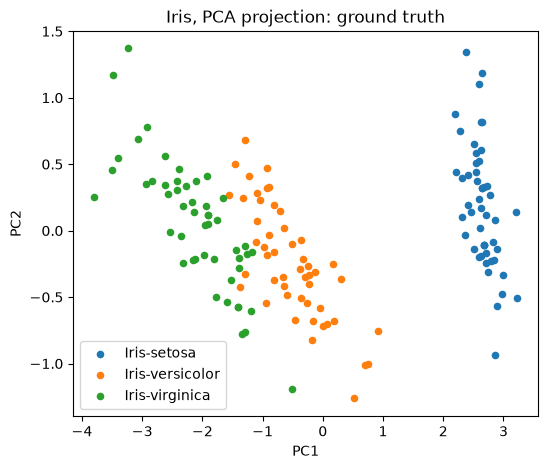

In [4]:
def pca(X, n_components=2):
    # PCA via eigendecomposition of the covariance matrix. Returns the projection and the explained variance ratio.
    Xc = X - X.mean(axis=0)
    cov = Xc.T @ Xc / (len(X) - 1)
    eigval, eigvec = np.linalg.eigh(cov)           # eigenvalues in ascending order
    order = np.argsort(eigval)[::-1]
    eigval, eigvec = eigval[order], eigvec[:, order]
    return Xc @ eigvec[:, :n_components], eigval / eigval.sum()

Z, evr = pca(X, 2)
print("explained variance ratio of the first two PCs:", evr[:2].round(3), "-> total", evr[:2].sum().round(3))

def plot2d(Z, labels, title, ax=None, names=None):
    ax = ax or plt.gca()
    for l in np.unique(labels):
        ax.scatter(Z[labels == l, 0], Z[labels == l, 1], s=20, label=(names[l] if names is not None else f"cluster {l}"))
    ax.set_title(title); ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.legend()

plt.figure(figsize=(6, 5))
plot2d(Z, y, "Iris, PCA projection: ground truth", names=class_names)
plt.show()

2. Perform hierarchical clustering with single linkage and Ward's linkage using `scipy` functions.
3. Plot the dendrogram and the datapoints in 2D, coloring now by cluster (cut the dendrogram to have the same number of clusters as the ground truth).

To quantify the agreement with the ground truth we use the *adjusted Rand index* (ARI: 1 = identical partitions, about 0 = random labels) and the contingency table (rows = true class, columns = cluster).

single linkage, cluster sizes: [50  2 98] ARI: 0.564
[[50  0  0]
 [ 0  0 50]
 [ 0  2 48]]
ward linkage, cluster sizes: [50 36 64] ARI: 0.731
[[50  0  0]
 [ 0  1 49]
 [ 0 35 15]]


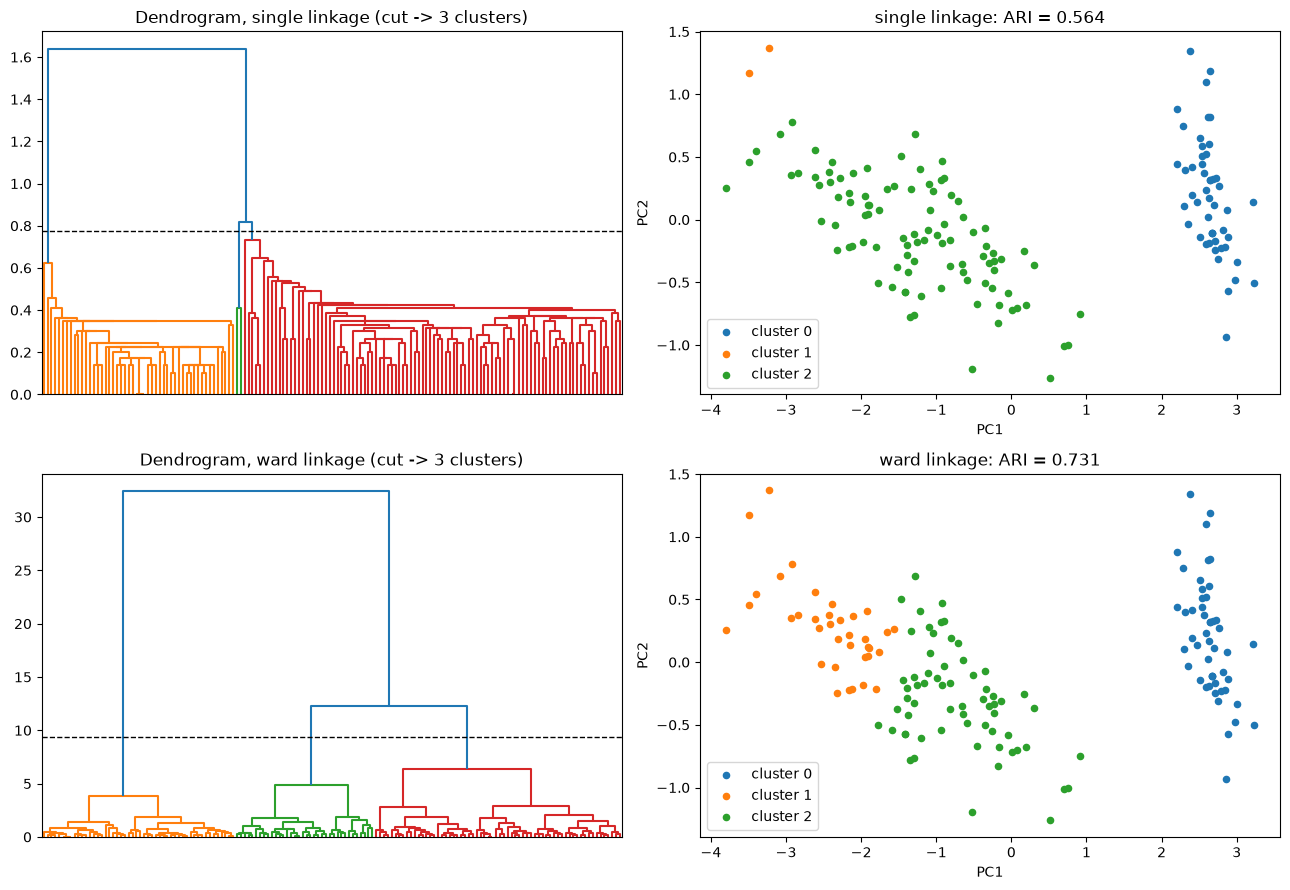

In [5]:
def contingency(true, pred):
    return np.array([[np.sum((true == a) & (pred == b)) for b in np.unique(pred)] for a in np.unique(true)])

hier = {}
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for row, method in enumerate(["single", "ward"]):
    Lk = linkage(X, method=method)                              # (n-1, 4) linkage matrix
    labels = fcluster(Lk, t=k_true, criterion="maxclust") - 1   # cut the tree to get k_true clusters
    hier[method] = labels
    # height of the cut: between the (k-1)-th and the k-th last merge
    cut = (Lk[-k_true, 2] + Lk[-(k_true - 1), 2]) / 2
    dendrogram(Lk, no_labels=True, color_threshold=cut, ax=axes[row, 0])
    axes[row, 0].axhline(cut, color="k", ls="--", lw=1)
    axes[row, 0].set_title(f"Dendrogram, {method} linkage (cut -> {k_true} clusters)")
    plot2d(Z, labels, f"{method} linkage: ARI = {adjusted_rand_score(y, labels):.3f}", ax=axes[row, 1])
    print(method, "linkage, cluster sizes:", np.bincount(labels), "ARI:", round(adjusted_rand_score(y, labels), 3))
    print(contingency(y, labels))
plt.tight_layout(); plt.show()

**Comments.** *Single* linkage merges the two closest *points* of two clusters, so it suffers from the **chaining effect**: versicolor and virginica touch each other, and the cut at $k=3$ isolates setosa and then splits off just a couple of outlying flowers, leaving one giant cluster (ARI $\approx 0.56$). *Ward* minimizes the increase of the within-cluster variance at every merge, which favors compact, similarly sized clusters and recovers the three species much better (ARI $\approx 0.73$), although the versicolor/virginica boundary is still imperfect.

# Exercise 2: spectral clustering
4. Implement your own version of spectral clustering.
5. Apply it to the dataset, setting $k_C$ to be the same of the ground truth (build the graph with $k$-NN having $k_{NN}=5$). Plot the datapoints in 2D, coloring by cluster.

The algorithm, step by step:
1. build the $k_{NN}$ graph and **symmetrize** it ($i\sim j$ if $j$ is among the neighbors of $i$ *or* vice versa);
2. make sure the graph is **connected**;
3. weight the edges with a **similarity** (decreasing function of the distance);
4. build the Laplacian and take the eigenvectors of its $k_C$ smallest eigenvalues;
5. run $k$-means on the rows of the eigenvector matrix.



### Step 1: the $k$-NN graph

In [6]:
def pairwise_dist(X):
    sq = (X ** 2).sum(axis=1)
    return np.sqrt(np.maximum(sq[:, None] - 2 * X @ X.T + sq[None, :], 0))

def knn_graph(D, k):
    # Boolean symmetric adjacency matrix of the k-NN graph (OR-symmetrization).
    n = len(D)
    idx = np.argsort(D, axis=1)[:, 1:k + 1]        # column 0 is the point itself (distance 0)
    A = np.zeros((n, n), dtype=bool)
    A[np.repeat(np.arange(n), k), idx.ravel()] = True   # directed: i -> its k nearest neighbors
    return A | A.T                                       # undirected: keep the edge if it exists in either direction

def knn_graph_inefficient(D, k):
    n = len(D)
    A = np.zeros((n, n), dtype=bool)
    for i in range(n):
        vicini = np.argsort(D[i])[1:k + 1]   # indici dei k punti più vicini a i (salto i stesso)
        for j in vicini:
            A[i, j] = True                    # arco orientato i -> j
    return A | A.T                            # simmetrizzazione

D = pairwise_dist(X)
A = knn_graph(D, k=5)
print("edges:", A.sum() // 2, "| degree min/mean/max:", A.sum(1).min(), A.sum(1).mean().round(2), A.sum(1).max())

edges: 513 | degree min/mean/max: 5 6.85 12


### Step 2: connectivity
The multiplicity of the eigenvalue $0$ of the Laplacian is the number of connected components. We find the components with a simple depth-first search.

In [17]:
from scipy.sparse.csgraph import connected_components
n_comp, comp = connected_components(D, directed=False)
comp

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], dtype=int32)

In [7]:
def connected_components(A):
    # Returns (number of components, label of each vertex) with an iterative depth-first search.
    n = len(A)
    comp = -np.ones(n, dtype=int)
    c = 0
    for s in range(n):
        if comp[s] >= 0:
            continue
        comp[s] = c
        stack = [s]
        while stack:
            u = stack.pop()
            for v in np.where(A[u])[0]:
                if comp[v] < 0:
                    comp[v] = c
                    stack.append(v)
        c += 1
    return c, comp

for k_nn in [3, 5, 7, 10, 15, 30]:
    n_comp, comp = connected_components(knn_graph(D, k_nn))
    print(f"k_NN = {k_nn:2d}: {n_comp} connected component(s), sizes {np.bincount(comp)}")

k_NN =  3: 2 connected component(s), sizes [ 50 100]
k_NN =  5: 2 connected component(s), sizes [ 50 100]
k_NN =  7: 2 connected component(s), sizes [ 50 100]
k_NN = 10: 2 connected component(s), sizes [ 50 100]
k_NN = 15: 2 connected component(s), sizes [ 50 100]
k_NN = 30: 1 connected component(s), sizes [150]


In [14]:
connected_components(knn_graph(D, 2))

(4,
 array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1,
        0, 0, 0, 0, 0, 0, 2, 2, 2, 2, 2, 2, 2, 3, 2, 2, 3, 2, 2, 2, 2, 2,
        2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
        2, 2, 2, 2, 2, 3, 2, 2, 2, 2, 3, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
        2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
        2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2]))

The graph is **not connected**, for every $k_{NN}$ up to 15 (it takes $k_{NN}=30$ to connect it): setosa is so far from the other two species that none of its flowers has a neighbor outside of it. With a disconnected graph the eigenvalue $0$ has multiplicity $>1$ and the Laplacian eigenvectors are just the indicator vectors of the components: the algorithm would only be able to separate setosa from the rest, in an arbitrary way.

A minimal fix that does not change the graph elsewhere: while there is more than one component, **add the single shortest edge between two different components**.

In [ ]:
from scipy.sparse.csgraph import connected_components

def connect_graph_inefficient(A, D):
    # While the graph has more than one connected component,
    # add the shortest edge joining two different components.
    A = A.copy()                                           # do not modify the input graph
    n_comp, comp = connected_components(A, directed=False) # comp[i] = component label of vertex i
    while n_comp > 1:
        best = np.inf                                      # shortest distance found so far
        for i in range(len(A)):
            for j in range(i + 1, len(A)):                 # visit each pair (i, j) once
                # only pairs in different components, and closer than the best so far
                if comp[i] != comp[j] and D[i, j] < best:
                    best, bi, bj = D[i, j], i, j           # remember the new best pair
        A[bi, bj] = A[bj, bi] = True                       # add the edge in both directions (A stays symmetric)
        print(f"adding edge ({bi}, {bj}), length {best:.3f}")
        n_comp, comp = connected_components(A, directed=False)  # recompute the components
    return A

In [ ]:
def connect_graph(A, D):
    # Adds, until the graph is connected, the shortest edge joining two different components.
    A = A.copy()
    n_comp, comp = connected_components(A)
    while n_comp > 1:
        different = comp[:, None] != comp[None, :]
        Dm = np.where(different, D, np.inf)
        i, j = np.unravel_index(np.argmin(Dm), Dm.shape)
        A[i, j] = A[j, i] = True
        print(f"  adding edge ({i}, {j}), length {D[i, j]:.3f}")
        n_comp, comp = connected_components(A)
    return A

A = connect_graph(knn_graph(D, k=5), D)
print("connected components:", connected_components(A)[0])

  adding edge (23, 98), length 1.640
connected components: 1


### Step 3: similarities
The weights of the edges are **similarities**, not distances. The naive choice is $s_{ij}=1$ on the edges; a better one is a decreasing function of the distance, here the Gaussian kernel
$$s_{ij}=\exp\!\left(-\frac{d_{ij}^2}{2\sigma^2}\right)\quad\text{if } i\sim j,\qquad s_{ij}=0 \text{ otherwise,}$$
with $\sigma$ set to the average length of the edges of the graph (so that the scale adapts to the data).

In [10]:
def similarity_matrix(A, D, kind="gaussian"):
    if kind == "binary":
        return A.astype(float)
    sigma = D[A].mean()                            # average edge length
    return np.where(A, np.exp(-D ** 2 / (2 * sigma ** 2)), 0.0)

W = similarity_matrix(A, D)
print("sigma =", D[A].mean().round(3), "| weights in [%.3f, %.3f]" % (W[A].min(), W[A].max()))

sigma = 0.387 | weights in [0.000, 1.000]


### Steps 4-5: Laplacian, eigenvectors, $k$-means
Given the weight matrix $W$ and the degree matrix $D_{deg}=\mathrm{diag}(\sum_j w_{ij})$ we implement the three Laplacians seen in class:

- unnormalized: $L=D_{deg}-W$ (eigenvectors used as they are);
- random walk: $L_{rw}=I-D_{deg}^{-1}W$, whose eigenvectors are obtained from the generalized problem $Lv=\lambda D_{deg}v$ (eigenvectors used as they are);
- symmetric: $L_{sym}=I-D_{deg}^{-1/2}WD_{deg}^{-1/2}$ (Ng-Jordan-Weiss: rows of the eigenvector matrix **normalized to unit length**).

We reuse the $k$-means from the previous labs (with $k$-means++ initialization and several restarts) for the last step.

cluster sizes: [37 50 63] | ARI: 0.745
[[ 0 50  0]
 [ 1  0 49]
 [36  0 14]]


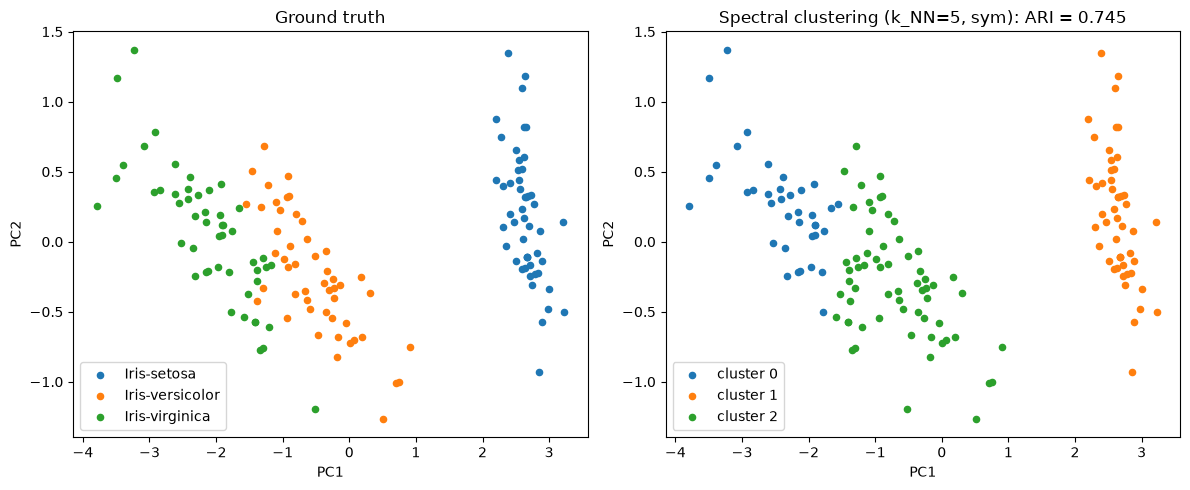

In [11]:
def kmeans(X, k, n_init=20, max_iter=300, rng=None):
    # Lloyd's k-means with k-means++ initialization; keeps the best of n_init runs (lowest squared loss).
    rng = rng or np.random.default_rng(0)
    best = (np.inf, None)
    for _ in range(n_init):
        C = X[[rng.integers(len(X))]]                                         # k-means++ initialization
        for _ in range(k - 1):
            d2 = ((X[:, None, :] - C[None]) ** 2).sum(-1).min(axis=1)
            C = np.vstack([C, X[rng.choice(len(X), p=d2 / d2.sum())]])
        for _ in range(max_iter):
            labels = ((X[:, None, :] - C[None]) ** 2).sum(-1).argmin(axis=1)
            newC = np.array([X[labels == j].mean(axis=0) if np.any(labels == j) else C[j] for j in range(k)])
            if np.allclose(newC, C):
                break
            C = newC
        loss = ((X - C[labels]) ** 2).sum()
        if loss < best[0]:
            best = (loss, labels)
    return best[1]


def spectral_embedding(W, k, laplacian="sym"):
    # Eigenvalues and the k-column embedding of the chosen Laplacian ("unnorm", "rw" or "sym").
    d = W.sum(axis=1)
    L = np.diag(d) - W
    if laplacian == "unnorm":
        eigval, eigvec = np.linalg.eigh(L)
        U = eigvec[:, :k]
    elif laplacian == "sym":
        Dm12 = np.diag(1 / np.sqrt(d))
        eigval, eigvec = np.linalg.eigh(Dm12 @ L @ Dm12)                      # = I - D^-1/2 W D^-1/2
        U = eigvec[:, :k]
        U = U / np.linalg.norm(U, axis=1, keepdims=True)                      # row normalization (NJW)
    elif laplacian == "rw":
        eigval, eigvec = np.linalg.eigh(np.diag(1 / np.sqrt(d)) @ L @ np.diag(1 / np.sqrt(d)))
        U = np.diag(1 / np.sqrt(d)) @ eigvec[:, :k]                           # generalized eigenvectors: v = D^-1/2 u
    else:
        raise ValueError(laplacian)
    return eigval, U


def spectral_clustering(W, k, laplacian="sym", seed=0):
    eigval, U = spectral_embedding(W, k, laplacian)
    return kmeans(U, k, rng=np.random.default_rng(seed))


labels_sc = spectral_clustering(W, k_true, "sym")
print("cluster sizes:", np.bincount(labels_sc), "| ARI:", round(adjusted_rand_score(y, labels_sc), 3))
print(contingency(y, labels_sc))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
plot2d(Z, y, "Ground truth", ax=axes[0], names=class_names)
plot2d(Z, labels_sc, f"Spectral clustering (k_NN=5, sym): ARI = {adjusted_rand_score(y, labels_sc):.3f}", ax=axes[1])
plt.tight_layout(); plt.show()

**Check.** The smallest eigenvalue of every Laplacian is $0$, and the **eigengap** heuristic suggests the number of clusters. Here the first two eigenvalues are both (numerically) almost $0$: the graph is *nearly* made of two components (setosa and the rest, joined by the single edge we added). After them the eigenvalues grow slowly, and the gap after the third one is not much larger than its neighbors: on iris the eigengap clearly says "2 clusters" but does not single out 3, because versicolor and virginica overlap. This is why we set $k_C$ to the number of classes.

10 smallest eigenvalues of L_sym: [-2.0837e-17  8.3185e-07  1.0036e-02  2.9890e-02  3.5260e-02  6.0496e-02
  7.3169e-02  1.1415e-01  1.6930e-01  1.7136e-01]
eigengaps: [8.3185e-07 1.0035e-02 1.9855e-02 5.3692e-03 2.5237e-02 1.2673e-02
 4.0980e-02 5.5153e-02 2.0562e-03]


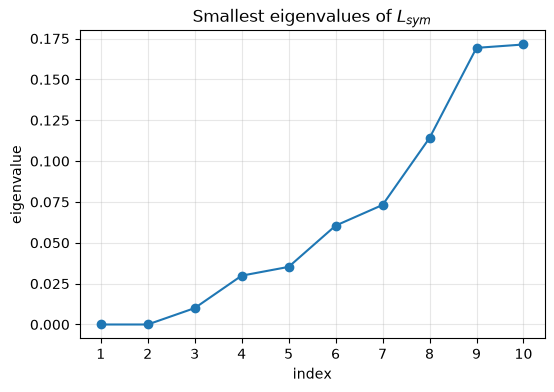

In [12]:
eigval, _ = spectral_embedding(W, 10, "sym")
print("10 smallest eigenvalues of L_sym:", np.array2string(eigval[:10], precision=4, suppress_small=False))
print("eigengaps:", np.array2string(np.diff(eigval[:10]), precision=4))

plt.figure(figsize=(6, 4))
plt.plot(range(1, 11), eigval[:10], "o-")
plt.xlabel("index"); plt.ylabel("eigenvalue"); plt.title("Smallest eigenvalues of $L_{sym}$")
plt.xticks(range(1, 11)); plt.grid(alpha=.3); plt.show()

# Bonus: where spectral clustering shines
$k$-means (and Ward) assume compact, roughly spherical clusters. Two interleaved half-moons (generated with `sklearn.datasets.make_moons`, used here only to generate the data) are a classic counterexample.

components of the 8-NN graph: 1


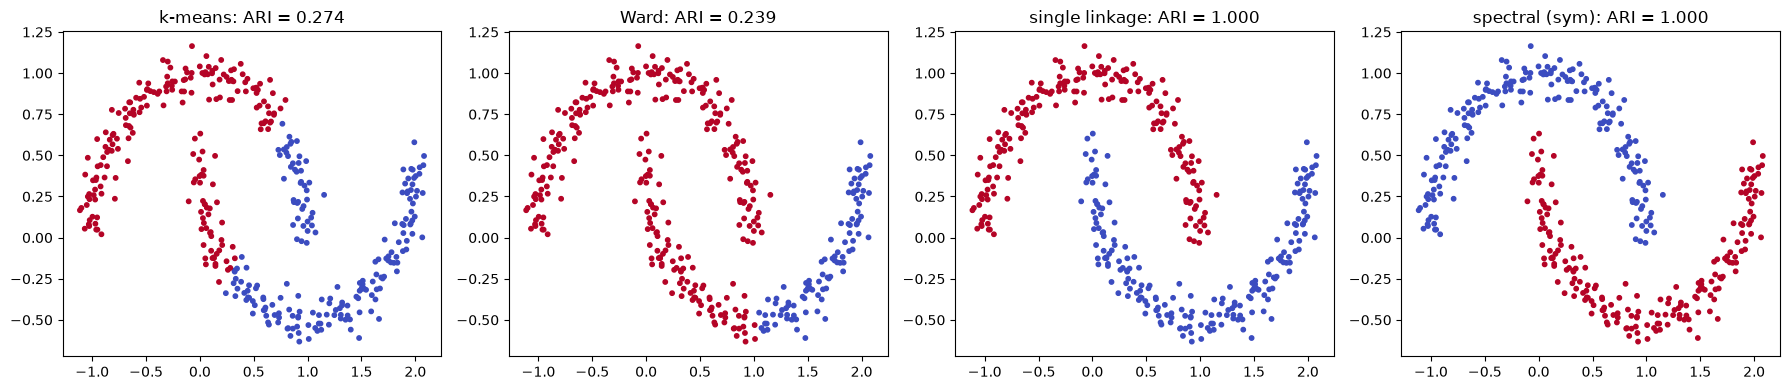

In [13]:
from sklearn.datasets import make_moons

Xm, ym = make_moons(n_samples=400, noise=0.07, random_state=0)
Dm = pairwise_dist(Xm)
Am = knn_graph(Dm, k=8)
print("components of the 8-NN graph:", connected_components(Am)[0])
Wm = similarity_matrix(Am, Dm)

res = {
    "k-means": kmeans(Xm, 2),
    "Ward": fcluster(linkage(Xm, "ward"), 2, "maxclust") - 1,
    "single linkage": fcluster(linkage(Xm, "single"), 2, "maxclust") - 1,
    "spectral (sym)": spectral_clustering(Wm, 2, "sym"),
}
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (name, lab) in zip(axes, res.items()):
    ax.scatter(Xm[:, 0], Xm[:, 1], c=lab, s=10, cmap="coolwarm")
    ax.set_title(f"{name}: ARI = {adjusted_rand_score(ym, lab):.3f}")
plt.tight_layout(); plt.show()

$k$-means and Ward cut the moons with a straight-ish boundary and fail (ARI $\approx 0.25$). Spectral clustering recovers the two moons perfectly because it works on the *connectivity* of the graph rather than on distances to centers. Single linkage also succeeds here, since the two moons are well separated and chaining is now an advantage: it follows the elongated shape, but it would break down as soon as noise bridges the two moons (try `noise=0.2`).